# Analytical Velocity

Copy of `monthly/AV-3-ver2.ipynb`. Changes (marked `# CHANGED` in the code):
1. one coastal band for every field: the band of CUTI / $W_L$ (`CUTI.ipynb`): round(109 km / dx) boxes, coast box included, on the CROCO ocean mask (before: a 111 km band on each field's own valid cells);
2. $Ek_{pump}$ excluded in the box next to land (Bordbar et al. 2021), where $W_c$ is largest;
3. paths to `../data/`.

$\
W_{\mathrm{c}} = \frac{2.07 \cdot Ek_c}{R_1} \cdot \mathrm{e}^{\,2.3026 \frac{x}{R_1}}
\
$

$
\text{AV}= Ek_{\text{pump}} + W_c
$

where $AV$ is in $ms^{-1}$ , $e$ is the Euler number and $x$ is the distance to the coast. 

* Wc is computed from the cross-shore Ekman transport evaluated at the coastline, and distributed offshore following an exponential decay over the first baroclinic Rossby radius $R_1$, such that $w_c$ reaches 10% of its coastal value at $x=R_1$ (Bordbar et al. 2021; Fennel 1999).
* Is important to take into consideration that in Boardbar paper, the coastal angle for Benguela is close to $0^{\circ}$ with the North, for which the rotation done is not needed there, and we will use the Uekman non rotated but geographical transport for building this index. However when the rotation is effective the Analytical velocity wouldn't work for the Peruvian Sea which angle is $45^{\circ}$

In [71]:
import xarray as xr
import math
import numpy as np
import matplotlib.pyplot as plt

DATA = '../data/'                                                 # CHANGED: paths

## Functions

In [72]:
def coastal_band_mask(ds, var, target_width_km=111):
    '''Coastal band of fixed cross-shore width; coast = easternmost valid cell per row.
    CHANGED: the band of CUTI.ipynb, n_cells boxes IN TOTAL, coast box included.'''
    da = ds[var]
    if 'time' in da.dims:
        da = da.isel(time=0)

    valid2d  = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon     = np.abs(lon_vals[1] - lon_vals[0])

    band = np.zeros_like(valid2d, dtype=bool)
    for j in range(valid2d.shape[0]):
        ocean_cols = np.where(valid2d[j, :])[0]
        if len(ocean_cols) == 0:
            continue
        i_coast = ocean_cols[-1]
        dx_km   = 6371.0 * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))
        band[j, max(i_coast - n_cells + 1, 0):i_coast + 1] = True

    return xr.DataArray(band & valid2d, dims=('lat', 'lon'),
                        coords={'lat': ds['lat'], 'lon': ds['lon']})


def on_grid(m, like):
    '''Boolean mask m on the lat/lon grid of `like` (same grid, nearest within 1e-3 deg).'''
    return m.reindex(lat=like.lat, lon=like.lon, method='nearest', tolerance=1e-3).fillna(False).astype(bool)


def seasonality(data):
    season = data.groupby('time.month').mean(dim='time')
    return season

## Data

In [73]:
lati1,lati2=-4,-17
mask_km = 109                                                     # CHANGED: band width of CUTI (was 111)

In [74]:
# CHANGED: one band for all fields, built (as in CUTI.ipynb) on the CROCO ocean mask carried by MLD.nc
ocean = np.isfinite(xr.open_dataset(DATA + 'MLD.nc').MLD.isel(time=0)).drop_vars('time')
mask  = coastal_band_mask(ocean.where(ocean).to_dataset(name='ocean'), 'ocean', mask_km)

# box next to land = easternmost ocean cell of each row (Ek_pump is excluded there)
i_coast  = ocean.cumsum('lon').argmax('lon')
coastbox = (xr.DataArray(np.arange(ocean.sizes['lon']), dims='lon', coords={'lon': ocean.lon}) == i_coast) & ocean

In [75]:
R_X = xr.open_dataset(DATA + 'Rossby_radius_and_X.nc').compute()
R_X = R_X.where(on_grid(mask, R_X)).sel(lon=slice(-85,None),lat=slice(lati2,lati1))
R_X

<xarray.Dataset> Size: 496kB
Dimensions:  (lat: 159, lon: 194)
Coordinates:
  * lon      (lon) float64 2kB -84.95 -84.87 -84.78 ... -69.03 -68.95 -68.87
  * lat      (lat) float64 1kB -16.99 -16.91 -16.83 ... -4.245 -4.162 -4.079
Data variables:
    R        (lat, lon) float64 247kB nan nan nan nan nan ... nan nan nan nan
    X        (lat, lon) float64 247kB nan nan nan nan nan ... nan nan nan nan

In [76]:
winds_c = xr.open_dataset(DATA + 'Winds_components_Lu.nc').compute()
Uek_inshore = (winds_c.U_ek_cross
        .isel(offshore=0)
        .swap_dims({'coast_point': 'lat'})
        .drop_vars(['coast_point', 'lon', 'bearing', 'distance', 'f', 'offshore']))
Uek_inshore

<xarray.DataArray 'U_ek_cross' (time: 432, lat: 221)> Size: 764kB
array([[0.47077047, 0.46868903, 0.46739847, ..., 5.60168058, 5.43658235,
        5.56174778],
       [0.50015188, 0.50011023, 0.50099314, ..., 3.21576567, 2.88127034,
        2.89439867],
       [0.52221533, 0.51689966, 0.51244225, ..., 1.60692423, 1.4340936 ,
        1.44019013],
       ...,
       [0.70361879, 0.69442059, 0.68506383, ..., 9.33127552, 9.2368636 ,
        9.4412787 ],
       [0.6886988 , 0.68435476, 0.68065091, ..., 9.83410705, 9.498648  ,
        9.70110201],
       [0.62637977, 0.6249985 , 0.62453954, ..., 7.71256828, 7.68518914,
        7.82504339]])
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat      (lat) float64 2kB -19.99 -19.92 -19.84 ... -2.249 -2.166 -2.082
Attributes:
    units:      m^2/s
    long_name:  Cross-shore Ekman transport (BUI)

In [77]:
e =math.e
r=R_X.R
x= R_X.X
Uek = Uek_inshore

Wc = ((2.07 * Uek)/r)*e**(-2.3026*x/r)
Wc #already in m/s

<xarray.DataArray (time: 432, lat: 159, lon: 194)> Size: 107MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]])
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat      (lat) float64 1kB -16.99 -16.91 -16.83 ... -4.245 -4.162 -4.079
  * lon      (lon) float64 2kB -84.95 -84.87 -84.78 ... -69.03 -68.95 -68.87

## Another Ekman Pump
* Pump calculated by finite differences

In [78]:
ekpump = xr.open_dataset(DATA + 'Ekman_pumping.nc').compute()
ekpump = ekpump.sel(lon=slice(-85,None),lat=slice(lati2,lati1))
ekpump_centered = ekpump.w_ek
ekpump_centered = ekpump_centered.assign_coords(lat=Wc.lat, lon=Wc.lon)
# CHANGED: same band as W_c, and Ek_pump excluded in the box next to land
band_ = on_grid(mask, Wc)
cbox_ = on_grid(coastbox, Wc)
ekpump_centered = ekpump_centered.where(band_ & ~cbox_)
ekpump_centered

<xarray.DataArray 'w_ek' (time: 432, lat: 159, lon: 194)> Size: 107MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]])
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat      (lat) float64 1kB -16.99 -16.91 -16.83 ... -4.245 -4.162 -4.079
  * lon      (lon) float64 2kB -84.95 -84.87 -84.78 ... -69.03 -68.95 -68.87

In [79]:
# rows where w_ek (finite differences) does not reach the boxes next to the coast:
# there it is undefined and AV = W_c (only the box next to land is excluded on purpose)
sel = dict(lat=slice(-16, -5))
undef = (band_ & ~cbox_ & ~np.isfinite(ekpump.w_ek.isel(time=0).assign_coords(lat=Wc.lat, lon=Wc.lon))).sel(**sel).sum('lon')
print('rows 5-16S:', int(band_.sel(**sel).any('lon').sum()),
      '| w_ek undefined in extra boxes next to the coast:', {int(k): int((undef == k).sum()) for k in np.unique(undef)})

rows 5-16S: 134 | w_ek undefined in extra boxes next to the coast: {0: 123, 1: 9, 2: 2}


In [80]:
AV_ = (ekpump_centered.fillna(0) + Wc).where(band_)                # CHANGED: AV = W_c where Ek_pump is excluded / undefined
AV_

<xarray.DataArray (time: 432, lat: 159, lon: 194)> Size: 107MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]])
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat      (lat) float64 1kB -16.99 -16.91 -16.83 ... -4.245 -4.162 -4.079
  * lon      (lon) float64 2kB -84.95 -84.87 -84.78 ... -69.03 -68.95 -68.87

boxes per row with AV (5-16S, median): 12


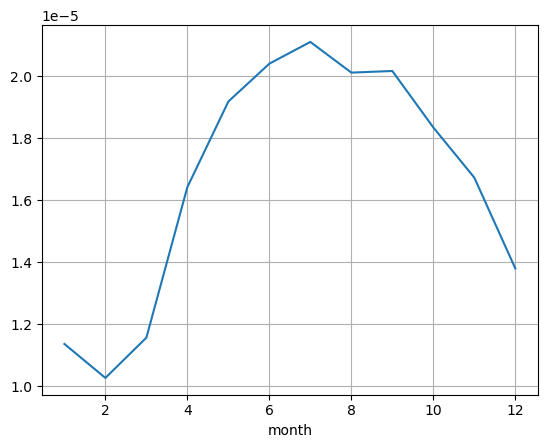

In [81]:
print('boxes per row with AV (5-16S, median):', int(np.isfinite(AV_.isel(time=0)).sel(lat=slice(-16, -5)).sum('lon').median()))
seasonality(AV_).sel(lat=slice(-16,-5)).mean(dim=('lon','lat')).plot()
plt.grid(True)

## AV vs CROCO $W_{MLD}$, per metre of coastline
Reference: `W_L` of `CUTI_BEUTI_HR_L_C.nc` (CROCO $W_{MLD}$ integrated over the row strip of CUTI ÷ coastline length `L_coast`). AV in the same units: summed across the band × row height ÷ `L_coast` (as in `Latitudinal`). 5–16°S = row means.

In [82]:
hr = xr.open_dataset(DATA + 'CUTI_BEUTI_HR_L_C.nc').sortby('lat_band').compute()
W_L = hr.W_L.rename(lat_band='lat')                                # m2/s per metre of coastline
L   = hr.L_coast.rename(lat_band='lat')
# row height: not stored in the _C file; CUTI_BEUTI_HR_L.nc has the same rows and L_coast and stores it
dy  = xr.open_dataset(DATA + 'CUTI_BEUTI_HR_L.nc').dy.sortby('lat_band').rename(lat_band='lat')

R  = 6371000.0
dx = R * np.cos(np.deg2rad(AV_.lat)) * np.deg2rad(1 / 12)          # m
L_av  = L.reindex(lat=AV_.lat, method='nearest', tolerance=0.02)
dy_av = dy.reindex(lat=AV_.lat, method='nearest', tolerance=0.02)
AV_L  = ((AV_ * dx).sum('lon', min_count=1) * dy_av / L_av).rename('AV')   # m2/s per metre of coastline

av_ts = AV_L.sel(lat=slice(-16, -5)).mean('lat')
w_ts  = W_L.sel(lat=slice(-16, -5)).mean('lat')
av_ts, w_ts = xr.align(av_ts, w_ts, join='inner')

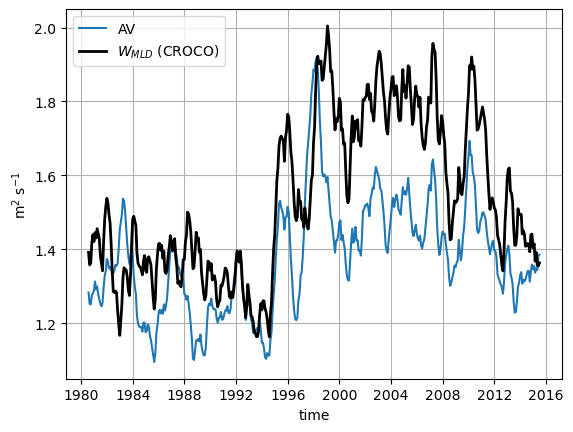

In [83]:
# 13-month running mean, 5-16S
av_ts.rolling(time=13, center=True).mean().plot(label='AV')
w_ts.rolling(time=13, center=True).mean().plot(label='$W_{MLD}$ (CROCO)', linewidth=2, color='black')
plt.ylabel('m$^2$ s$^{-1}$'); plt.grid(True); plt.legend()

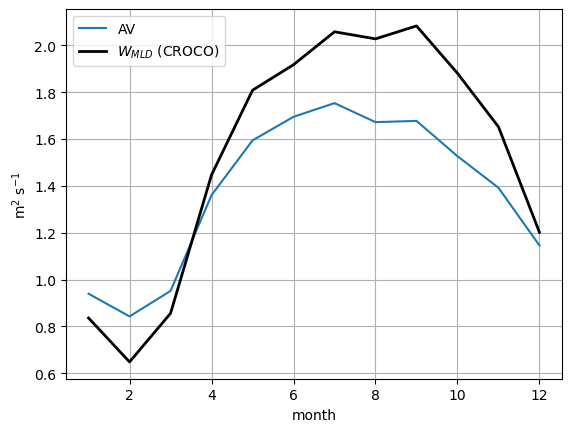

In [84]:
# seasonal cycle, 5-16S
seasonality(av_ts).plot(label='AV')
seasonality(w_ts).plot(label='$W_{MLD}$ (CROCO)', linewidth=2, color='black')
plt.ylabel('m$^2$ s$^{-1}$'); plt.grid(True); plt.legend()

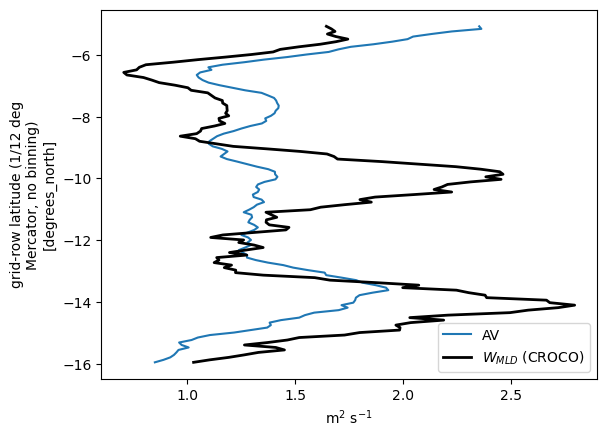

In [85]:
# latitudinal profile of the time mean (13-row running mean)
AV_L.mean('time').rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5)).plot(y='lat', label='AV')
W_L.mean('time').rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5)).plot(y='lat', label='$W_{MLD}$ (CROCO)', color='black', linewidth=2)
plt.xlabel('m$^2$ s$^{-1}$'); plt.legend()

In [86]:
# numbers (5-16S row means)
r_s  = np.corrcoef(seasonality(av_ts), seasonality(w_ts))[0, 1]
r_13 = xr.corr(av_ts.rolling(time=13, center=True).mean(), w_ts.rolling(time=13, center=True).mean()).item()
print(f'seasonal r = {r_s:.2f}  |  13-month running mean r = {r_13:.2f}  |  mean AV / mean W_MLD = {float(av_ts.mean() / w_ts.mean()):.2f}')

seasonal r = 0.99  |  13-month running mean r = 0.78  |  mean AV / mean W_MLD = 0.90


### Why AV is damped: split into $W_c$ and $Ek_{pump}$
Seasonal cycles (5–16°S, per metre of coastline) of $W_{MLD}$, AV, its two parts, and the Ekman transports.
$W_c$ is the Ekman transport $Ek_c$ = `U_ek_cross` at `offshore=0` (the offshore edge of the band, ~90 km in the file's `distance`; with no flux through the coast it is the total Ekman divergence of the band, i.e. $Ek_t$) times a nearly constant factor (≈ 0.6: 2.07/2.3026 = 0.90 from the formula, the rest from the band width and the coast geometry), so its seasonal amplitude is reduced by the same factor as its mean. $W_{MLD}$ keeps almost the full Ekman amplitude and loses a nearly constant offset (onshore geostrophic flow). $Ek_{pump}$ adds a small, almost constant amount.

m2/s                         1     2     3     4     5     6     7     8     9    10    11    12   ampl.   mean
$W_{MLD}$ (CROCO, W_L)    0.84  0.65  0.86  1.45  1.81  1.92  2.06  2.03  2.08  1.88  1.65  1.20    1.44   1.53
AV                        0.94  0.84  0.95  1.36  1.59  1.70  1.75  1.67  1.68  1.53  1.39  1.15    0.91   1.38
$W_c$ part                0.85  0.72  0.81  1.22  1.49  1.58  1.63  1.57  1.57  1.44  1.30  1.07    0.91   1.27
$Ek_{pump}$ part          0.09  0.13  0.14  0.14  0.11  0.12  0.12  0.11  0.10  0.09  0.09  0.07    0.06   0.11
$U^{Ek}$ (CUTI file)      1.45  1.26  1.43  2.07  2.47  2.62  2.72  2.61  2.62  2.39  2.17  1.79    1.46   2.13
$Ek_t$ (band edge, offshore=0)  1.41  1.18  1.34  2.02  2.46  2.61  2.69  2.58  2.59  2.37  2.15  1.76    1.51   2.10

W_c / Ek_t per month: [0.61 0.61 0.61 0.6  0.6  0.61 0.61 0.61 0.61 0.61 0.61 0.61]  (mean 0.61)


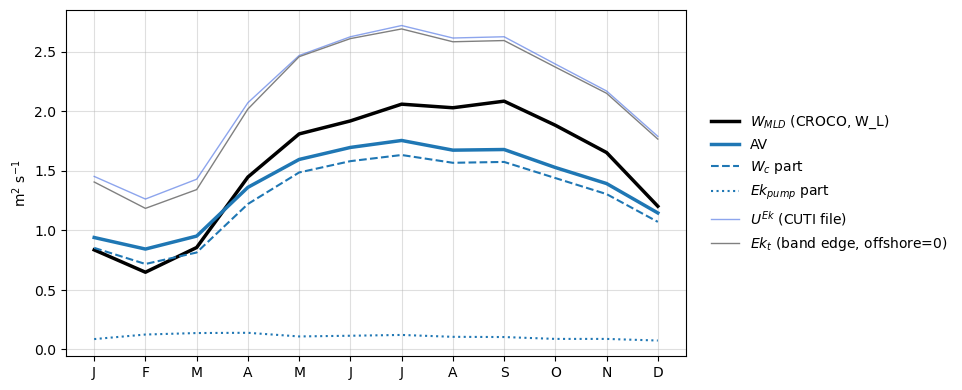

In [87]:
# split of AV into W_c and Ek_pump, same units as above (per metre of coastline, 5-16S row means)
perL = lambda v: ((v * dx).sum('lon', min_count=1) * dy_av / L_av).sel(lat=slice(-16, -5)).mean('lat')

parts = {
    '$W_{MLD}$ (CROCO, W_L)': w_ts,
    'AV':                     av_ts,
    '$W_c$ part':             perL(Wc.where(band_)),
    '$Ek_{pump}$ part':       perL(ekpump_centered.fillna(0).where(band_)),
    '$U^{Ek}$ (CUTI file)':   hr.U_ek.sel(lat_band=slice(-16, -5)).mean('lat_band'),
    '$Ek_t$ (band edge, offshore=0)':  Uek_inshore.sortby('lat').sel(lat=slice(-16, -5)).mean('lat'),
}
seas = {k: seasonality(v) for k, v in parts.items()}

print(f"{'m2/s':24s}" + ''.join(f'{m:>6d}' for m in range(1, 13)) + '   ampl.   mean')
for k, s in seas.items():
    v = s.values
    print(f'{k:24s}' + ''.join(f'{x:6.2f}' for x in v) + f'   {v.max() - v.min():5.2f}  {v.mean():5.2f}')
ratio = seas['$W_c$ part'] / seas['$Ek_t$ (band edge, offshore=0)']
print(f'\nW_c / Ek_t per month: {np.round(ratio.values, 2)}  (mean {float(ratio.mean()):.2f})')

styles = {'$W_{MLD}$ (CROCO, W_L)': dict(color='black', lw=2.5), 'AV': dict(color='tab:blue', lw=2.5),
          '$W_c$ part': dict(color='tab:blue', ls='--'), '$Ek_{pump}$ part': dict(color='tab:blue', ls=':'),
          '$U^{Ek}$ (CUTI file)': dict(color='royalblue', lw=1, alpha=0.6), '$Ek_t$ (band edge, offshore=0)': dict(color='0.5', lw=1)}
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, s in seas.items():
    ax.plot(s.month, s.values, label=k, **styles[k])
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list('JFMAMJJASOND'))
ax.set_ylabel('m$^2$ s$^{-1}$'); ax.grid(True, alpha=0.4)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.show()

In [88]:
AV_ = AV_.to_dataset(name='AV')
AV_['Epumping'] = ekpump_centered
AV_['Wc'] = Wc.where(band_)

In [89]:
AV_.to_netcdf(DATA + 'AV.nc')